# LC Binodal Phase Diagram – Analysis Pipeline

Transforms raw 3D MATILDA.FT density output into a 1D z-axis profile and extracts binodal coexistence concentrations via a double-tanh fit.

**Workflow**
1. Read `grid_densities_chi_*.bin` → planar-averaged LC volume fraction φ(z)
2. Visualise the slab profile
3. Fit double-tanh to extract φ_iso and φ_nem
4. Collect (χN, φ_iso, φ_nem) over all chi steps → phase diagram

In [86]:
import struct
import glob
import os
import re
import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

---
## Configuration – edit these paths before running

In [ ]:
# Path to a specific signac job workspace
# e.g. the nematic job
JOB_PATH = "/home/gabriel/Tests/LC_binodal/workspace/bf6aed8457b6ce4e94d713d36ae8f107"

# Particle type index for LC (0-based, so type 2 in LAMMPS → index 1 here)
LC_TYPE_INDEX = 1

# Number of trailing frames to use for the z-profile.
# 1  → final frame only (closest to equilibration).
# 3  → average of last 3 frames (reduces noise if profile is noisy).
N_FRAMES_FOR_PROFILE = 1

# Box grid dimensions (must match the job's Nx, Ny, Nz)
NX, NY, NZ = 24, 24, 144

# Physical box length along z (Lz = Nz * dz, with dz set by the simulation)
# We read this from the binary header, but set a fallback here.
LZ_FALLBACK = 144.0


---
## Phase 1 – Read binary density files and compute φ_LC(z)

In [88]:
def read_density_frames(filepath):
    """
    Parse a MATILDA.FT grid_densities*.bin file.

    Binary layout (from io_utils.cu :: init_binary_output / write_binary):
      Header  (written once at file creation):
        int32   Dim
        int32   Nx[Dim]
        float32 L[Dim]
        int32   ntypes
      Frames  (one per write_binary() call, appended):
        float32  all_rho[M * ntypes]   where M = Nx[0]*Nx[1]*...*Nx[Dim-1]
        Grid ordering: C-order (last index fastest),
        i.e. index = ix*Ny*Nz + iy*Nz + iz

    Returns
    -------
    header : dict  with keys 'Dim', 'Nx', 'L', 'ntypes', 'M'
    frames : np.ndarray  shape (n_frames, ntypes, M)
    """
    with open(filepath, 'rb') as fh:
        raw = fh.read()

    offset = 0

    # --- Header ---
    dim = struct.unpack_from('<i', raw, offset)[0];  offset += 4
    nx  = struct.unpack_from(f'<{dim}i', raw, offset);  offset += 4 * dim
    L   = struct.unpack_from(f'<{dim}f', raw, offset);  offset += 4 * dim
    ntypes = struct.unpack_from('<i', raw, offset)[0];  offset += 4

    M = 1
    for n in nx:
        M *= n

    header = {'Dim': dim, 'Nx': nx, 'L': L, 'ntypes': ntypes, 'M': M}

    # --- Frames ---
    frame_bytes = M * ntypes * 4   # float32
    n_frames    = (len(raw) - offset) // frame_bytes

    if n_frames == 0:
        raise RuntimeError(f"No density frames found in {filepath}")

    data = np.frombuffer(raw, dtype='<f4', count=n_frames * M * ntypes,
                         offset=offset)
    frames = data.reshape(n_frames, ntypes, M)

    return header, frames


def z_profile(frames, header, lc_type_index=1, n_frames=1):
    """
    Compute the planar-averaged LC volume fraction along z.

    Uses only the last `n_frames` frames (default 1 = final frame only,
    which is closest to equilibration).  Set n_frames=3 to average the
    last three frames if the single-frame profile is too noisy.

    Parameters
    ----------
    frames           : ndarray  (n_total_frames, ntypes, M)
    header           : dict from read_density_frames
    lc_type_index    : int  0-based type index for the LC species
    n_frames         : int  number of trailing frames to average over

    Returns
    -------
    z_coords : ndarray  shape (Nz,)  physical z positions
    phi_z    : ndarray  shape (Nz,)  LC volume fraction per z-slice
    """
    nx_vals = header['Nx']          # (Nx, Ny, Nz)
    Lx, Ly, Lz = header['L']
    Nx_g, Ny_g, Nz_g = nx_vals

    # Slice to the last n_frames frames
    n_frames = min(n_frames, frames.shape[0])
    frames = frames[-n_frames:]

    # Density is stored as all_rho[type*M + grid_index] per frame;
    # here frames[frame, type, grid_index] with C-order index = ix*Ny*Nz + iy*Nz + iz
    lc_rho    = frames[:, lc_type_index, :]   # (n_frames, M)
    total_rho = frames.sum(axis=1)             # (n_frames, M)

    # Avoid division by zero on empty grid cells
    with np.errstate(invalid='ignore', divide='ignore'):
        phi_lc = np.where(total_rho > 0, lc_rho / total_rho, 0.0)

    # MATILDA grid index: id = x + y*Nx + z*Ny*Nx  (x fastest, z slowest)
    # so the flat M elements must be reshaped as (Nz, Ny, Nx).
    phi_4d = phi_lc.reshape(-1, Nz_g, Ny_g, Nx_g)

    # Average over selected frames (axis 0) and over y, x (axes 2, 3) → shape (Nz,)
    phi_z = phi_4d.mean(axis=(0, 2, 3))

    # z-coordinate array: cell centres, box runs from -Lz/2 to +Lz/2
    dz = Lz / Nz_g
    z_coords = -Lz / 2.0 + (np.arange(Nz_g) + 0.5) * dz

    return z_coords, phi_z


In [89]:
# Quick test on a single file
test_files = sorted(glob.glob(os.path.join(JOB_PATH, '*_grid_densities_chi_*.bin')))
print(f"Found {len(test_files)} density files")
if test_files:
    print("First file:", test_files[0])
    h, f = read_density_frames(test_files[0])
    print("Header:", h)
    print(f"Frames shape: {f.shape}  →  {f.shape[0]} frames, {h['ntypes']} types, M={h['M']}")
    print(f"Using last {N_FRAMES_FOR_PROFILE} frame(s) for z-profile")


Found 14 density files
First file: /home/gabriel/Tests/LC_binodal/workspace/dc1c091d3162b3c77fd9071f699cc6fa/grid_densities_chi_0.0.bin
Header: {'Dim': 3, 'Nx': (24, 24, 144), 'L': (24.0, 24.0, 144.0), 'ntypes': 2, 'M': 82944}
Frames shape: (21, 2, 82944)  →  21 frames, 2 types, M=82944
Using last 1 frame(s) for z-profile


---
## Phase 2 – Visualise slab profile for one chi step

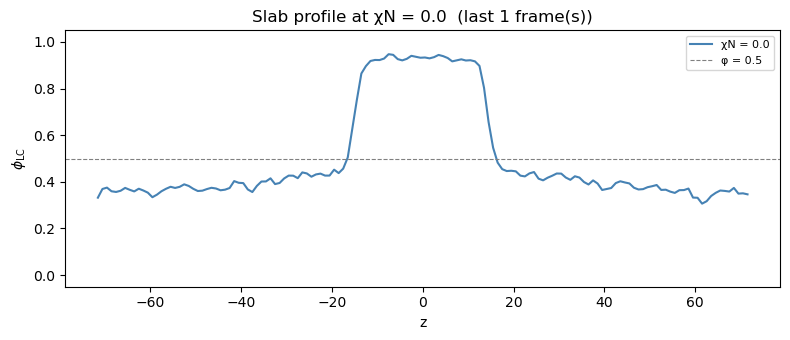

In [90]:
def plot_z_profile(z, phi, chi_N, ax=None, **kwargs):
    """Line plot of φ_LC(z) for a single chi*N value."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(z, phi, label=f'χN = {chi_N:.1f}', **kwargs)
    ax.set_xlabel('z')
    ax.set_ylabel(r'$\phi_{\mathrm{LC}}$')
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, ls='--', color='grey', lw=0.8, label='φ = 0.5')
    ax.legend(fontsize=8)
    return ax


# Pick the first (highest chi) scan file to inspect
if test_files:
    h, f = read_density_frames(test_files[0])
    z, phi = z_profile(f, h, lc_type_index=LC_TYPE_INDEX, n_frames=N_FRAMES_FOR_PROFILE)

    # Extract chi*N from filename (e.g. grid_densities_chi_6.5.bin → 6.5)
    chi_val = float(re.search(r'chi_([\d.]+)\.bin', test_files[0]).group(1))

    fig, ax = plt.subplots(figsize=(8, 3.5))
    plot_z_profile(z, phi, chi_val, ax=ax, color='steelblue')
    ax.set_title(f'Slab profile at χN = {chi_val:.1f}  (last {N_FRAMES_FOR_PROFILE} frame(s))')
    plt.tight_layout()
    plt.show()


---
## Phase 2b – Trajectory convergence: profiles at 25 / 50 / 75 / 100 % of a run

Select one `grid_densities_chi_*.bin` file and visualise how the z-profile
evolves over the production run to judge whether the system has settled.

Available χN values: [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5]
Trajectory file: grid_densities_chi_1.5.bin  (χN = 1.5)
Total frames in file: 21
Frame indices used: [5, 10, 15, 20]


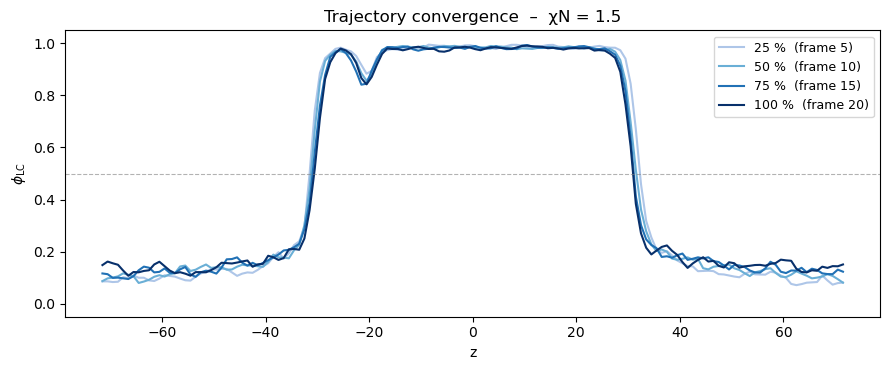

In [103]:
# ── Configuration ────────────────────────────────────────────────────────────
# Set CHI_N_TRAJ to a specific chi*N value (e.g. 3.0) to inspect that step.
# Set to None to auto-select the highest chi file available.
CHI_N_TRAJ = 1.5

# ── Resolve file ─────────────────────────────────────────────────────────────
all_chi_files = sorted(
    glob.glob(os.path.join(JOB_PATH, '*_grid_densities_chi_*.bin')),
    key=lambda f: float(re.search(r'chi_([\d.]+)\.bin', f).group(1)),
    reverse=True,
)
if not all_chi_files:
    raise FileNotFoundError(f'No grid_densities_chi_*.bin files found in {JOB_PATH}')

available_chi = [float(re.search(r'chi_([\d.]+)\.bin', f).group(1)) for f in all_chi_files]
print(f'Available χN values: {sorted(available_chi)}')

if CHI_N_TRAJ is None:
    TRAJ_FILE = all_chi_files[0]   # highest chi
else:
    match = [f for f, c in zip(all_chi_files, available_chi) if c == float(CHI_N_TRAJ)]
    if not match:
        raise ValueError(f'χN={CHI_N_TRAJ} not found. Available: {sorted(available_chi)}')
    TRAJ_FILE = match[0]

chi_label_val = float(re.search(r'chi_([\d.]+)\.bin', TRAJ_FILE).group(1))
print(f'Trajectory file: {os.path.basename(TRAJ_FILE)}  (χN = {chi_label_val:.1f})')

h_traj, frames_traj = read_density_frames(TRAJ_FILE)
n_total = frames_traj.shape[0]
print(f'Total frames in file: {n_total}')

if n_total < 2:
    print('Not enough frames to show trajectory convergence (need ≥ 2).')
else:
    # Frame indices at 25 / 50 / 75 / 100 % of the run
    fracs   = [0.25, 0.50, 0.75, 1.00]
    indices = [max(0, int(round(q * (n_total - 1)))) for q in fracs]
    labels  = ['25 %', '50 %', '75 %', '100 %']
    colors  = ['#aec6e8', '#6aafd6', '#2171b5', '#08306b']

    print('Frame indices used:', indices)

    fig, ax = plt.subplots(figsize=(9, 3.8))

    for idx, label, color in zip(indices, labels, colors):
        single_frame = frames_traj[idx:idx+1]   # shape (1, ntypes, M)
        z_t, phi_t = z_profile(single_frame, h_traj,
                                lc_type_index=LC_TYPE_INDEX, n_frames=1)
        ax.plot(z_t, phi_t, color=color, lw=1.5, label=f'{label}  (frame {idx})')

    ax.axhline(0.5, ls='--', color='grey', lw=0.8, alpha=0.6)
    ax.set_xlabel('z')
    ax.set_ylabel(r'$\phi_{\mathrm{LC}}$')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f'Trajectory convergence  –  χN = {chi_label_val:.1f}')
    ax.legend(fontsize=9, loc='upper right')
    plt.tight_layout()
    plt.show()


---
## Phase 3 – Double-tanh fit

In [ ]:
def double_tanh(z, phi_iso, phi_nem, z1, z2, w):
    """
    phi(z) = phi_iso + (phi_nem - phi_iso)/2 * [tanh((z-z1)/w) - tanh((z-z2)/w)]

    Slab centred between z1 and z2 with interface half-width w.
    """
    return phi_iso + 0.5 * (phi_nem - phi_iso) * (
        np.tanh((z - z1) / w) - np.tanh((z - z2) / w)
    )


def _profile_stats(z, phi_z):
    """
    Return (phi_center_avg, phi_edge_avg, delta_phi) where
    delta_phi > 0 means LC is enriched in the box centre (normal slab geometry).
    Uses middle 30% as centre and outer 15% each side as edges.
    """
    Nz = len(phi_z)
    c_lo, c_hi = int(0.35 * Nz), int(0.65 * Nz)
    e = int(0.15 * Nz)
    phi_center = phi_z[c_lo:c_hi].mean()
    phi_edge   = np.concatenate([phi_z[:e], phi_z[-e:]]).mean()
    return phi_center, phi_edge, phi_center - phi_edge


def fit_double_tanh(z, phi_z, min_delta=0.05, max_w_frac=0.25, min_r2=0.85):
    """
    Fit the double-tanh model to a planar-averaged profile.

    Returns
    -------
    popt    : array  [phi_iso, phi_nem, z1, z2, w]  or None
    pcov    : 2-D covariance matrix or None
    success : bool

    The fit is rejected (success=False) when:
      - the profile is nearly homogeneous (|delta_phi| < min_delta), or
      - curve_fit raises, or
      - the fitted phi_nem - phi_iso < min_delta (degenerate solution), or
      - the interface width w > max_w_frac * Lz (interfaces too broad; no real slab), or
      - the interfaces overlap: |z2-z1| < 2*w (slab squeezed out), or
      - the R2 of the fit < min_r2 (curve does not describe the data).

    Parameters
    ----------
    min_delta   : float  minimum |delta_phi| pre-check and post-fit contrast
    max_w_frac  : float  maximum allowed w as fraction of Lz (default 0.25)
    min_r2      : float  minimum R2 of double-tanh fit (default 0.85)
    """
    Lz    = z[-1] - z[0] + (z[1] - z[0])   # full box length
    z_mid = 0.5 * (z[0] + z[-1])

    phi_center, phi_edge, delta_phi = _profile_stats(z, phi_z)

    # Pre-check: reject if there is no meaningful phase separation
    if abs(delta_phi) < min_delta:
        return None, None, False

    # Initial guesses derived from the actual profile structure
    if delta_phi > 0:
        # Normal geometry: LC-rich slab in the centre
        phi_nem_0, phi_iso_0 = phi_center, phi_edge
    else:
        # Inverted (unusual) -- still try
        phi_nem_0, phi_iso_0 = phi_edge, phi_center

    # Clamp initial guesses into [0, 1] with a small margin
    phi_iso_0 = float(np.clip(phi_iso_0, 0.01, 0.99))
    phi_nem_0 = float(np.clip(phi_nem_0, 0.01, 0.99))

    p0 = [phi_iso_0, phi_nem_0,
          z_mid - 0.25 * Lz,   # z1 left interface
          z_mid + 0.25 * Lz,   # z2 right interface
          1.0]

    lo = [0.0,  0.0,  z[0],  z[0],  1e-4]
    hi = [1.0,  1.0,  z[-1], z[-1], Lz]

    try:
        popt, pcov = curve_fit(
            double_tanh, z, phi_z,
            p0=p0, bounds=(lo, hi),
            maxfev=10000,
        )
    except (RuntimeError, ValueError) as exc:
        warnings.warn(f'curve_fit failed: {exc}')
        return None, None, False

    # Normalise so phi_iso < phi_nem (fit is symmetric under swap + z1<->z2)
    if popt[0] > popt[1]:
        popt[0], popt[1] = popt[1], popt[0]

    # Post-fit sanity: reject degenerate amplitude
    if popt[1] - popt[0] < min_delta:
        warnings.warn(f'Fit degenerate: phi_nem-phi_iso = {popt[1]-popt[0]:.4f}')
        return None, None, False

    w  = popt[4]
    z1, z2 = popt[2], popt[3]
    slab_width = abs(z2 - z1)

    # Reject if interface width is too large relative to the box
    if w > max_w_frac * Lz:
        warnings.warn(f'Interface too broad: w={w:.2f} > {max_w_frac}*Lz={max_w_frac*Lz:.2f}')
        return None, None, False

    # Reject if the interfaces overlap (no coherent slab exists)
    if slab_width < 2.0 * w:
        warnings.warn(f'Interfaces overlap: slab_width={slab_width:.2f} < 2*w={2*w:.2f}')
        return None, None, False

    # Goodness-of-fit: R2 must exceed min_r2
    residuals = phi_z - double_tanh(z, *popt)
    ss_res = np.dot(residuals, residuals)
    ss_tot = np.sum((phi_z - phi_z.mean()) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else 0.0
    if r2 < min_r2:
        warnings.warn(f'Poor fit quality: R2={r2:.3f} < {min_r2}')
        return None, None, False

    return popt, pcov, True



def eval_fit_concentrations(z, popt):
    """
    Extract physically meaningful coexistence concentrations from a fitted
    double-tanh by *evaluating* the curve at the box center and edges,
    rather than reading the asymptotic parameters popt[0]/popt[1] directly.

    When interfaces are broad relative to the box (near the critical point),
    the asymptotic phi_nem parameter is unconstrained and can be pushed to
    the upper bound by the optimizer even though the actual peak concentration
    is much lower.

    Returns
    -------
    phi_iso_actual : float  mean of fitted curve at box edges
    phi_nem_actual : float  value of fitted curve at box centre
    """
    z_mid = 0.5 * (z[0] + z[-1])
    phi_nem_actual = float(double_tanh(z_mid, *popt))
    phi_iso_actual = float(0.5 * (double_tanh(z[0], *popt)
                                  + double_tanh(z[-1], *popt)))
    return phi_iso_actual, phi_nem_actual

def plot_fit(z, phi_z, popt, chi_N, ax=None):
    """Overlay the fitted curve on top of the data."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(z, phi_z, '.', ms=3, color='steelblue', label='data')
    z_fine = np.linspace(z[0], z[-1], 500)
    ax.plot(z_fine, double_tanh(z_fine, *popt), '-', color='tomato',
            lw=1.5, label='double-tanh fit')
    phi_iso_act, phi_nem_act = eval_fit_concentrations(z, popt)
    ax.axhline(phi_iso_act, ls=\':\', color=\'orange\',  lw=1, label=rf\'$\phi_{{iso}}$={phi_iso_act:.3f}\')
    ax.axhline(phi_nem_act, ls=\':\', color=\'seagreen\', lw=1, label=rf\'$\phi_{{nem}}$={phi_nem_act:.3f}\')
    ax.set_xlabel('z');  ax.set_ylabel(r'$\phi_{\mathrm{LC}}$')
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f'\u03c7N = {chi_N:.1f}')
    ax.legend(fontsize=7)
    return ax


# Demo fit on the first file
if test_files:
    popt, pcov, ok = fit_double_tanh(z, phi)
    if ok:
        print(f'phi_iso = {popt[0]:.4f},  phi_nem = {popt[1]:.4f}')
        print(f'z1 = {popt[2]:.2f},  z2 = {popt[3]:.2f},  w = {popt[4]:.3f}')
        fig, ax = plt.subplots(figsize=(8, 3.5))
        plot_fit(z, phi, popt, chi_val, ax=ax)
        plt.tight_layout();  plt.show()
    else:
        print('Fit did not converge or profile is homogeneous for this file.')


---
## Phase 4 – Binodal point extraction over all chi steps

---
## Phase 4b – Phase diagram plot

In [ ]:
def mean_plateau_fallback(z, phi_z):
    """
    Fallback when the double-tanh fit fails.
    phi_nem  = mean of middle 20% of box
    phi_iso  = mean of first and last 10% of box
    """
    Nz = len(phi_z)
    mid_lo = int(0.40 * Nz)
    mid_hi = int(0.60 * Nz)
    edge    = int(0.10 * Nz)

    phi_nem = float(np.mean(phi_z[mid_lo:mid_hi]))
    phi_iso = float(np.mean(np.concatenate([phi_z[:edge], phi_z[-edge:]])))
    return phi_iso, phi_nem


def extract_binodal_points(job_path, lc_type_index=1, n_frames=1, plot_fits=False,
                           min_delta=0.05, min_contrast=0.05):
    """
    Loop over all grid_densities_chi_*.bin files in job_path,
    extract (chi_N, phi_iso, phi_nem), and return as a sorted array.

    A chi value is included only when the system shows genuine phase separation:
      1. The raw z-profile centre-minus-edge contrast exceeds min_delta.
      2. The double-tanh fit passes all geometric and R2 checks.
      3. The *evaluated* coexistence contrast phi_nem - phi_iso >= min_contrast.
    Points that fail any criterion are skipped (reported as mixed/homogeneous).

    Parameters
    ----------
    job_path      : str   path to signac job workspace
    lc_type_index : int   0-based LC species index
    n_frames      : int   number of trailing frames to use for z-profile
    plot_fits     : bool  show per-chi fit plots
    min_delta     : float minimum centre-minus-edge phi contrast to attempt a fit
    min_contrast  : float minimum evaluated phi_nem - phi_iso to accept a point

    Returns
    -------
    results           : ndarray  shape (N, 3)  columns: [chi_N, phi_iso, phi_nem]
    all_chi_evaluated : list  all chi_N values found in files (accepted + rejected)
    """
    files = sorted(
        [f for f in glob.glob(os.path.join(job_path, '*_grid_densities_chi_*.bin'))
         if '_chunk' not in os.path.basename(f)],
        key=lambda f: float(re.search(r'chi_([\d.]+)\.bin', f).group(1)),
        reverse=True,
    )

    if not files:
        raise FileNotFoundError(
            f"No grid_densities_chi_*.bin files found in {job_path}"
        )

    rows = []
    all_chi_evaluated = []   # all chi values present in files
    for fp in files:
        chi_N = float(re.search(r'chi_([\d.]+)\.bin', fp).group(1))
        all_chi_evaluated.append(chi_N)

        try:
            h, frames = read_density_frames(fp)
        except Exception as exc:
            warnings.warn(f'Could not read {fp}: {exc}')
            continue

        z, phi_z = z_profile(frames, h, lc_type_index=lc_type_index, n_frames=n_frames)

        phi_center, phi_edge, delta_phi = _profile_stats(z, phi_z)

        # Skip this chi value entirely if the raw profile shows no separation
        if abs(delta_phi) < min_delta:
            print(f'  \u03c7N={chi_N:5.1f}  \u0394\u03c6={delta_phi:.4f}  [homogeneous \u2013 skipped]')
            continue

        popt, pcov, ok = fit_double_tanh(z, phi_z, min_delta=min_delta)

        if ok:
            phi_iso, phi_nem = eval_fit_concentrations(z, popt)
            method = 'fit'
            if plot_fits:
                fig, ax = plt.subplots(figsize=(7, 3))
                plot_fit(z, phi_z, popt, chi_N, ax=ax)
                plt.tight_layout();  plt.show()
        else:
            # Fallback: use direct plateau means, but still enforce contrast
            phi_iso, phi_nem = mean_plateau_fallback(z, phi_z)
            method = 'fallback'
            warnings.warn(f'chi*N={chi_N:.1f}: used mean-plateau fallback.')

        # Final contrast gate: both fit and fallback must show real separation
        if phi_nem - phi_iso < min_contrast:
            print(f'  \u03c7N={chi_N:5.1f}  contrast={phi_nem-phi_iso:.4f} < {min_contrast}  [mixed \u2013 skipped]')
            continue

        rows.append((chi_N, phi_iso, phi_nem))
        print(f'  \u03c7N={chi_N:5.1f}  \u03c6_iso={phi_iso:.4f}  \u03c6_nem={phi_nem:.4f}  [{method}]')

    results = np.array(rows) if rows else np.empty((0, 3))
    results_sorted = results[np.argsort(results[:, 0])] if len(results) else results
    return results_sorted, all_chi_evaluated


# Run over the selected job
print(f'Processing job: {JOB_PATH}')
binodal_data, _ = extract_binodal_points(
    JOB_PATH, lc_type_index=LC_TYPE_INDEX, n_frames=N_FRAMES_FOR_PROFILE, plot_fits=False
)
print(f'\nExtracted {len(binodal_data)} binodal points.')


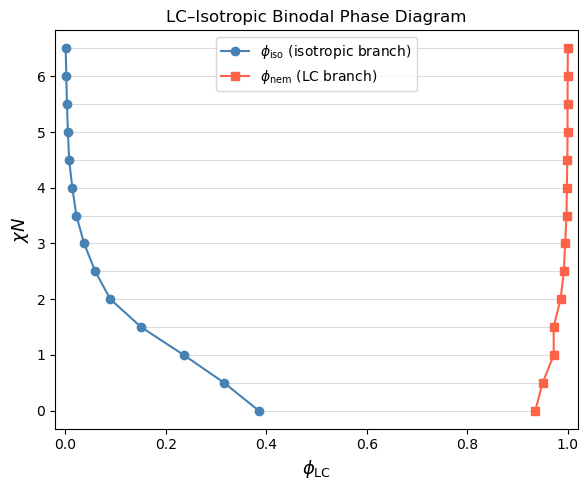

Saved binodal_phase_diagram.png


In [94]:
fig, ax = plt.subplots(figsize=(6, 5))

if binodal_data.size > 0:
    chi_N_vals = binodal_data[:, 0]
    phi_iso    = binodal_data[:, 1]
    phi_nem    = binodal_data[:, 2]

    ax.plot(phi_iso, chi_N_vals, 'o-', color='steelblue',  label=r'$\phi_{\mathrm{iso}}$ (isotropic branch)')
    ax.plot(phi_nem, chi_N_vals, 's-', color='tomato',     label=r'$\phi_{\mathrm{nem}}$ (LC branch)')

    # Connect coexistence tie-lines
    for chi, pi, pn in zip(chi_N_vals, phi_iso, phi_nem):
        ax.plot([pi, pn], [chi, chi], '-', color='grey', lw=0.5, alpha=0.4)

ax.set_xlabel(r'$\phi_{\mathrm{LC}}$', fontsize=13)
ax.set_ylabel(r'$\chi N$',             fontsize=13)
ax.set_xlim(-0.02, 1.02)
ax.set_title('LC–Isotropic Binodal Phase Diagram')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(JOB_PATH, 'binodal_phase_diagram.png'), dpi=150)
plt.show()
print('Saved binodal_phase_diagram.png')

---
## Optional – compare all three LC phases side by side

In [ ]:
import signac
from collections import defaultdict

PROJECT_PATH = "/home/gabriel/Tests/LC_binodal"
project = signac.get_project(PROJECT_PATH)

# Minimum fraction of replicas that must show phase separation
# for a chi*N value to appear on the phase diagram.
# 0.5 = majority rule; raise to 0.75 to require 3/4 replicas.
MIN_SEPARATED_FRACTION = 0.5

# -- Collect binodal data from all jobs, grouped by lc_phase ------------------
phase_data     = defaultdict(list)   # phase -> list of (N,3) accepted arrays
phase_all_chi  = defaultdict(list)   # phase -> list of chi lists (all evaluated)
phase_mu       = {}                  # phase -> maier_saupe

for job in project:
    phase = job.sp.lc_phase
    phase_mu[phase] = job.sp.maier_saupe
    try:
        data, all_chi = extract_binodal_points(
            job.path, lc_type_index=LC_TYPE_INDEX, n_frames=N_FRAMES_FOR_PROFILE
        )
    except FileNotFoundError:
        print(f'No data for {phase} job {job.id[:8]}, skipping.')
        continue
    phase_all_chi[phase].append(all_chi)
    if data.size > 0:
        phase_data[phase].append(data)


def average_binodal(arrays, all_chi_lists, min_fraction=0.5):
    """
    Given a list of (N_i, 3) arrays [chi_N, phi_iso, phi_nem] and the
    corresponding list of all-chi lists (one per replica), compute the
    quorum-aware average binodal.

    For each chi*N in the union of all evaluated values:
      - n_total   = number of replicas that ran at that chi*N
      - n_sep     = number of replicas that showed phase separation
      - fraction  = n_sep / n_total
    The point is included only if fraction >= min_fraction.

    Returns a (M, 7) array:
      [chi_N, mean_phi_iso, std_phi_iso, mean_phi_nem, std_phi_nem,
       n_separated, n_total]
    """
    # Union of all chi values ever evaluated across replicas
    chi_union = sorted(set().union(*[set(np.round(c, 1)) for c in all_chi_lists]))

    rows = []
    for chi in chi_union:
        # How many replicas were run at this chi?
        n_total = sum(1 for cl in all_chi_lists if any(abs(c - chi) < 0.05 for c in cl))

        # Which arrays have an accepted (phase-separated) point at this chi?
        iso_vals = [a[np.isclose(a[:, 0], chi), 1][0]
                    for a in arrays if np.any(np.isclose(a[:, 0], chi))]
        nem_vals = [a[np.isclose(a[:, 0], chi), 2][0]
                    for a in arrays if np.any(np.isclose(a[:, 0], chi))]
        n_sep = len(iso_vals)

        if n_total == 0:
            continue
        fraction = n_sep / n_total
        if fraction < min_fraction:
            print(f'  chi*N={chi:.1f}: {n_sep}/{n_total} separated ({fraction:.0%}) -- below threshold, skipped')
            continue

        rows.append([
            chi,
            np.mean(iso_vals), np.std(iso_vals) if len(iso_vals) > 1 else 0.0,
            np.mean(nem_vals), np.std(nem_vals) if len(nem_vals) > 1 else 0.0,
            n_sep, n_total,
        ])

    return np.array(rows) if rows else np.empty((0, 7))  # (M, 7)


# -- Plot ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))
colors = {'isotropic': 'grey', 'nematic': 'steelblue', 'smectic': 'tomato'}

for phase in sorted(phase_data, key=lambda p: phase_mu[p]):
    arrays   = phase_data[phase]
    all_chi  = phase_all_chi[phase]
    mu       = phase_mu[phase]
    color    = colors.get(phase, 'black')
    n_reps   = len(all_chi)   # total replicas evaluated
    print(f'\n{phase} (mu={mu}): {len(arrays)} replica(s) with any separation, {n_reps} total')

    avg = average_binodal(arrays, all_chi, min_fraction=MIN_SEPARATED_FRACTION)
    if avg.size == 0:
        print(f'  No binodal points survived the quorum filter.')
        continue

    chi_N_vals   = avg[:, 0]
    mean_phi_iso = avg[:, 1];  std_phi_iso = avg[:, 2]
    mean_phi_nem = avg[:, 3];  std_phi_nem = avg[:, 4]
    n_sep_arr    = avg[:, 5].astype(int)
    n_tot_arr    = avg[:, 6].astype(int)

    ax.errorbar(mean_phi_iso, chi_N_vals,
                xerr=std_phi_iso if n_reps > 1 else None,
                fmt='o-',  color=color, label=f'{phase} \u03c6_iso (\u03bc={mu})')
    ax.errorbar(mean_phi_nem, chi_N_vals,
                xerr=std_phi_nem if n_reps > 1 else None,
                fmt='s--', color=color, label=f'{phase} \u03c6_nem (\u03bc={mu})')

    # Annotate each point with n_sep/n_total fraction
    for phi_i, chi_i, ns, nt in zip(mean_phi_iso, chi_N_vals, n_sep_arr, n_tot_arr):
        if ns < nt:   # only annotate partial separation
            ax.text(phi_i - 0.01, chi_i, f'{ns}/{nt}',
                    fontsize=6, color=color, ha='right', va='center', alpha=0.7)

    # Connect tip
    tip_chi = chi_N_vals[0]
    if tip_chi > 0.0:
        ax.plot([mean_phi_iso[0], mean_phi_nem[0]], [tip_chi, tip_chi],
                '-', color=color, lw=1.2)

ax.set_xlabel(r'$\phi_{\mathrm{LC}}$', fontsize=13)
ax.set_ylabel(r'$\chi N$',             fontsize=13)
ax.set_xlim(-0.02, 1.02)
ax.set_title('LC\u2013Isotropic Binodal: all phases')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_PATH, 'binodal_all_phases.png'), dpi=150)
plt.show()
print('Saved binodal_all_phases.png')
